In [1]:

# P3 - Step 1A: Environment setup

%pip -q install scikit-learn pandas numpy matplotlib seaborn joblib

import sys
import random
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

PROJECT_DIR = Path("/content/P3_Supply_Chain_Demand_Forecasting")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Project directory:", PROJECT_DIR)
print("Environment setup completed.")


Python: 3.13.16
Pandas: 2.2.3
NumPy: 2.1.3
Scikit-learn: 1.6.1
Project directory: /content/P3_Supply_Chain_Demand_Forecasting
Environment setup completed.


In [2]:

# P3 - Step 1B: Generate synthetic supply chain demand data

rng = np.random.default_rng(RANDOM_STATE)

n_rows = 15000
n_skus = 100
n_regions = 5
n_days = 365

dates = pd.date_range("2025-01-01", periods=n_days, freq="D")

sku_ids = rng.choice(
    [f"SKU_{i:03d}" for i in range(1, n_skus + 1)],
    size=n_rows
)

regions = rng.choice(
    [f"REGION_{i}" for i in range(1, n_regions + 1)],
    size=n_rows
)

date_values = rng.choice(dates, size=n_rows)

promotion_discount = rng.choice(
    [0, 0.05, 0.10, 0.15, 0.20, 0.30],
    size=n_rows,
    p=[0.45, 0.10, 0.15, 0.12, 0.10, 0.08]
)

temperature_c = rng.normal(25, 7, size=n_rows).clip(-5, 45)
rainfall_mm = rng.gamma(shape=1.5, scale=8, size=n_rows).clip(0, 100)
shipping_delay_days = rng.poisson(1.5, size=n_rows).clip(0, 10)

sku_categories = {
    f"SKU_{i:03d}": rng.choice(
        ["Electronics", "Home", "Fashion", "Grocery", "Sports"]
    )
    for i in range(1, n_skus + 1)
}

sku_base_demand = {
    f"SKU_{i:03d}": rng.uniform(15, 120)
    for i in range(1, n_skus + 1)
}

region_effects = {
    f"REGION_{i}": rng.uniform(-10, 15)
    for i in range(1, n_regions + 1)
}

day_of_year = pd.DatetimeIndex(date_values).dayofyear.to_numpy()
day_of_week = pd.DatetimeIndex(date_values).dayofweek.to_numpy()
month = pd.DatetimeIndex(date_values).month.to_numpy()

base_demand = np.array([sku_base_demand[s] for s in sku_ids])
regional_effect = np.array([region_effects[r] for r in regions])

# Synthetic seasonal and nonlinear demand relationships
seasonality = 15 * np.sin(2 * np.pi * day_of_year / 365)
weekend_effect = np.where(day_of_week >= 5, 8, 0)
promotion_effect = 150 * promotion_discount
weather_effect = (
    0.7 * (temperature_c - 25)
    - 0.25 * rainfall_mm
)
shipping_effect = -3.5 * shipping_delay_days

# Add nonlinear promotion/weather interaction and random noise
interaction_effect = (
    45 * promotion_discount * (temperature_c > 30)
)

noise = rng.normal(0, 12, size=n_rows)

demand = (
    base_demand
    + regional_effect
    + seasonality
    + weekend_effect
    + promotion_effect
    + weather_effect
    + shipping_effect
    + interaction_effect
    + noise
)

order_volume = np.maximum(0, np.round(demand)).astype(int)

demand_df = pd.DataFrame({
    "date": date_values,
    "sku_id": sku_ids,
    "region": regions,
    "sku_category": [sku_categories[s] for s in sku_ids],
    "promotion_discount": promotion_discount,
    "temperature_c": temperature_c.round(2),
    "rainfall_mm": rainfall_mm.round(2),
    "shipping_delay_days": shipping_delay_days,
    "day_of_week": day_of_week,
    "month": month,
    "day_of_year": day_of_year,
    "order_volume": order_volume
})

# Save raw synthetic dataset
raw_path = PROJECT_DIR / "supply_chain_demand.csv"
demand_df.to_csv(raw_path, index=False)

print("Dataset generated successfully.")
print("Rows:", len(demand_df))
print("Unique SKUs:", demand_df["sku_id"].nunique())
print("Regions:", demand_df["region"].nunique())
print("Date range:", demand_df["date"].min().date(),
      "to", demand_df["date"].max().date())
print("Missing values:", demand_df.isna().sum().sum())
print("Duplicate rows:", demand_df.duplicated().sum())
print("\nDataset preview:")
display(demand_df.head())
print("\nDemand summary:")
display(demand_df["order_volume"].describe().to_frame().round(2))
print("\nSaved to:", raw_path)


Dataset generated successfully.
Rows: 15000
Unique SKUs: 100
Regions: 5
Date range: 2025-01-01 to 2025-12-31
Missing values: 0
Duplicate rows: 0

Dataset preview:


,date,sku_id,region,sku_category,promotion_discount,temperature_c,rainfall_mm,shipping_delay_days,day_of_week,month,day_of_year,order_volume
0,2025-03-26,SKU_009,REGION_1,Fashion,0.05,26.73,16.00,2,2,3,85,75
1,2025-05-07,SKU_078,REGION_3,Fashion,0.00,13.23,1.04,6,2,5,127,38
2,2025-11-11,SKU_066,REGION_3,Electronics,0.00,18.98,18.02,2,1,11,315,0
3,2025-02-07,SKU_044,REGION_4,Home,0.15,26.45,7.74,2,4,2,38,88
4,2025-02-09,SKU_044,REGION_3,Home,0.00,15.49,10.92,1,6,2,40,38



Demand summary:


,order_volume
count,15000.00
mean,68.60
std,39.16
min,0.00
25%,38.75
50%,67.00
75%,98.00
max,200.00



Saved to: /content/P3_Supply_Chain_Demand_Forecasting/supply_chain_demand.csv


Dataset shape: (15000, 12)

Data types and missing values:


,dtype,missing_values
date,datetime64[ns],0
sku_id,object,0
region,object,0
sku_category,object,0
promotion_discount,float64,0
temperature_c,float64,0
rainfall_mm,float64,0
shipping_delay_days,int64,0
day_of_week,int64,0
month,int64,0


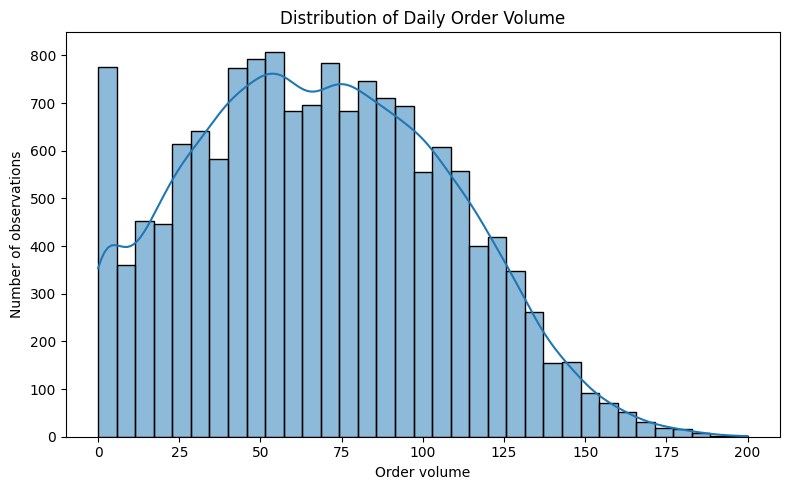

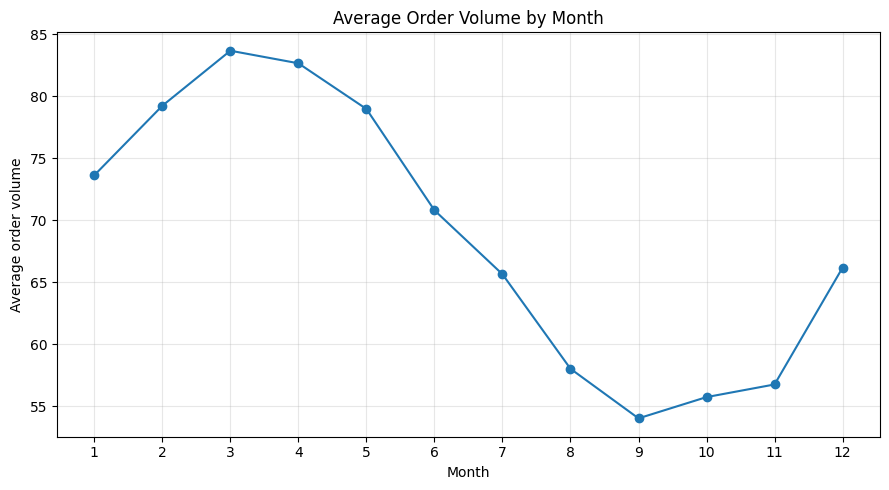

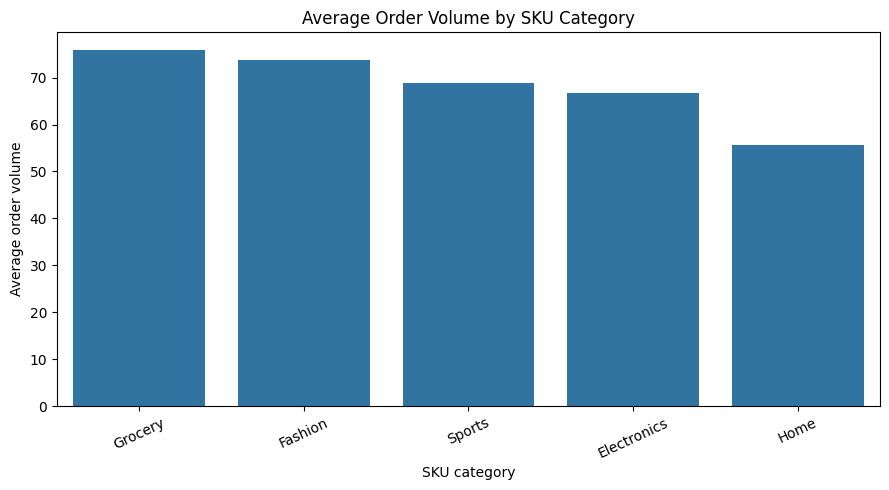

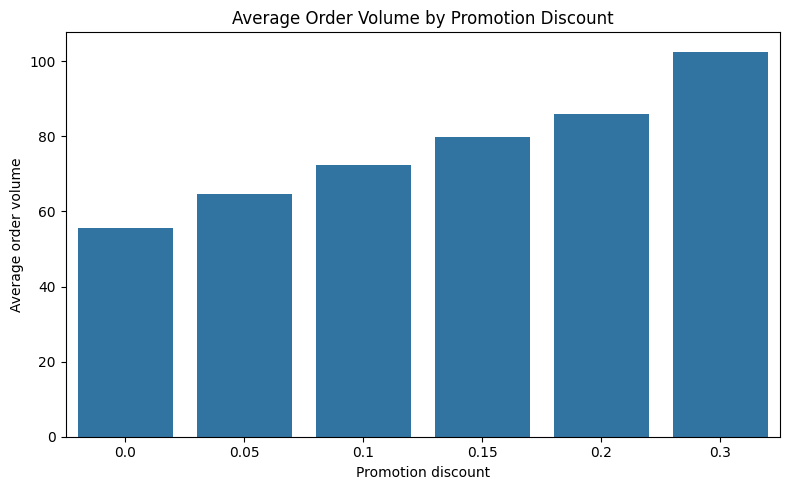

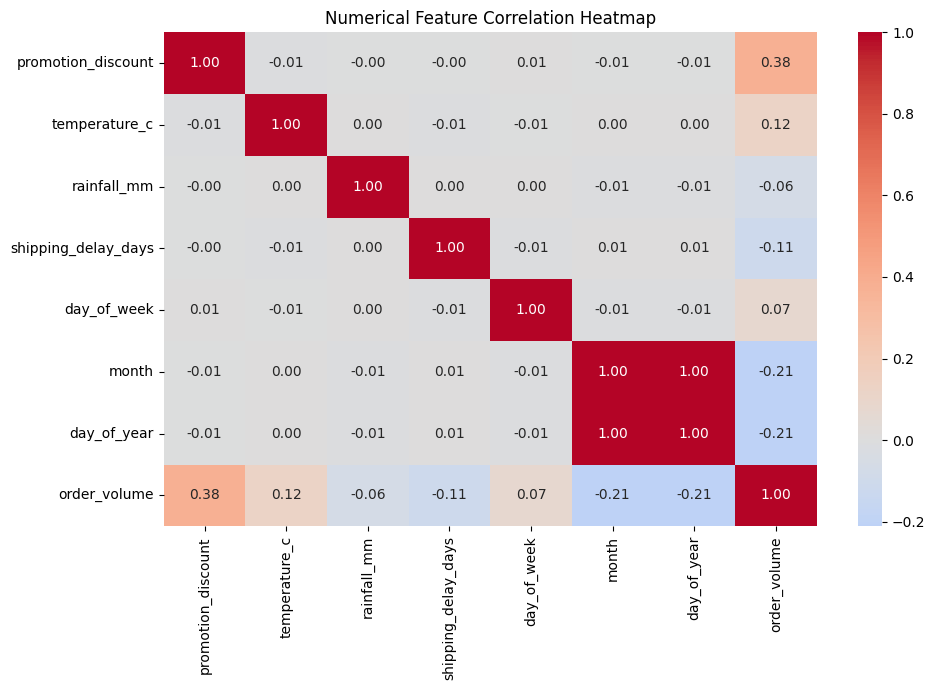


Average order volume: 68.6
Standard deviation: 39.16

Monthly demand summary:


,average_order_volume
month,
1,73.62
2,79.23
3,83.67
4,82.66
5,78.97
6,70.80
7,65.63
8,58.01
9,54.01


In [3]:

# P3 - Step 2: Exploratory Data Analysis

# Load the generated dataset
demand_df = pd.read_csv(
    PROJECT_DIR / "supply_chain_demand.csv",
    parse_dates=["date"]
)

print("Dataset shape:", demand_df.shape)
print("\nData types and missing values:")
display(pd.DataFrame({
    "dtype": demand_df.dtypes.astype(str),
    "missing_values": demand_df.isna().sum()
}))

# 1. Distribution of daily order volume
plt.figure(figsize=(8, 5))
sns.histplot(demand_df["order_volume"], bins=35, kde=True)
plt.title("Distribution of Daily Order Volume")
plt.xlabel("Order volume")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

# 2. Average demand by month
monthly_demand = (
    demand_df.groupby("month")["order_volume"]
    .mean()
)

plt.figure(figsize=(9, 5))
monthly_demand.plot(marker="o")
plt.title("Average Order Volume by Month")
plt.xlabel("Month")
plt.ylabel("Average order volume")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Average demand by SKU category
category_demand = (
    demand_df.groupby("sku_category")["order_volume"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=category_demand.index, y=category_demand.values)
plt.title("Average Order Volume by SKU Category")
plt.xlabel("SKU category")
plt.ylabel("Average order volume")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# 4. Average demand by promotion discount
promotion_demand = (
    demand_df.groupby("promotion_discount")["order_volume"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=promotion_demand,
    x="promotion_discount",
    y="order_volume"
)
plt.title("Average Order Volume by Promotion Discount")
plt.xlabel("Promotion discount")
plt.ylabel("Average order volume")
plt.tight_layout()
plt.show()

# 5. Correlation among numerical variables
numeric_columns = [
    "promotion_discount", "temperature_c", "rainfall_mm",
    "shipping_delay_days", "day_of_week", "month",
    "day_of_year", "order_volume"
]

plt.figure(figsize=(10, 7))
sns.heatmap(
    demand_df[numeric_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)
plt.title("Numerical Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

print("\nAverage order volume:", round(demand_df["order_volume"].mean(), 2))
print("Standard deviation:", round(demand_df["order_volume"].std(), 2))
print("\nMonthly demand summary:")
display(monthly_demand.round(2).to_frame("average_order_volume"))


In [4]:

# P3 - Step 3: Feature Engineering and Data Splitting

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load data
demand_df = pd.read_csv(
    PROJECT_DIR / "supply_chain_demand.csv",
    parse_dates=["date"]
)

target_column = "order_volume"

# Use features available in the generated pipeline table
categorical_features = ["sku_id", "region", "sku_category"]

numeric_features = [
    "promotion_discount",
    "temperature_c",
    "rainfall_mm",
    "shipping_delay_days",
    "day_of_week",
    "month",
    "day_of_year",
]

X_raw = demand_df[categorical_features + numeric_features].copy()
y = demand_df[target_column].astype(float).copy()

# One-hot encode categorical variables
X = pd.get_dummies(
    X_raw,
    columns=categorical_features,
    dtype=float
)

# Split into train (70%), validation (15%), and test (15%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE
)

# Fit feature scaler using training data only
feature_scaler = StandardScaler()

X_train_scaled = feature_scaler.fit_transform(X_train)
X_val_scaled = feature_scaler.transform(X_val)
X_test_scaled = feature_scaler.transform(X_test)

# Scale the target for neural network training
target_mean = float(y_train.mean())
target_std = float(y_train.std())

y_train_scaled = (y_train.to_numpy() - target_mean) / target_std
y_val_scaled = (y_val.to_numpy() - target_mean) / target_std

print("Feature preparation completed.")
print("Encoded feature count:", X.shape[1])
print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))
print("Train/validation/test:",
      f"{len(X_train)/len(X):.0%} /",
      f"{len(X_val)/len(X):.0%} /",
      f"{len(X_test)/len(X):.0%}")
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled validation shape:", X_val_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)
print("Target mean:", round(target_mean, 2))
print("Target standard deviation:", round(target_std, 2))


Feature preparation completed.
Encoded feature count: 117
Training rows: 10500
Validation rows: 2250
Test rows: 2250
Train/validation/test: 70% / 15% / 15%
Scaled training shape: (10500, 117)
Scaled validation shape: (2250, 117)
Scaled test shape: (2250, 117)
Target mean: 68.9
Target standard deviation: 39.1


In [5]:

# P3 - Step 4: Build and train an initial MLP model

%pip -q install tensorflow

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
import time

tf.keras.utils.set_random_seed(RANDOM_STATE)

def build_mlp(
    input_dim,
    hidden_units=(128, 64),
    learning_rate=0.001,
    dropout_rate=0.20,
    l2_strength=0.0001
):
    model = keras.Sequential()
    model.add(layers.Input(shape=(input_dim,)))

    for units in hidden_units:
        model.add(layers.Dense(
            units,
            kernel_regularizer=regularizers.l2(l2_strength),
            use_bias=False
        ))
        model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        model.add(layers.Dropout(dropout_rate))

    model.add(layers.Dense(1, activation="linear"))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="mse",
        metrics=["mae"]
    )
    return model

mlp_model = build_mlp(
    input_dim=X_train_scaled.shape[1],
    hidden_units=(128, 64),
    learning_rate=0.001,
    dropout_rate=0.20,
    l2_strength=0.0001
)

mlp_model.summary()

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

start_time = time.time()

history = mlp_model.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=60,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)

training_seconds = time.time() - start_time

print(f"\nTraining time: {training_seconds:.2f} seconds")
print("Epochs completed:", len(history.history["loss"]))
print("Best validation loss:", round(min(history.history["val_loss"]), 4))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        14,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,001 (93.75 KB)

 Trainable params: 23,617 (92.25 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/60
83/83 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.7782 - mae: 0.6792 - val_loss: 0.2512 - val_mae: 0.3847
Epoch 2/60
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4287 - mae: 0.5075 - val_loss: 0.1861 - val_mae: 0.3251
Epoch 3/60
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3476 - mae: 0.4554 - val_loss: 0.1708 - val_mae: 0.3101
Epoch 4/60
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3012 - mae: 0.4209 - val_loss: 0.1610 - val_mae: 0.3014
Epoch 5/60
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.2657 - mae: 0.3946 - val_loss: 0.1555 - val_mae: 0.2949
Epoch 6/60
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.2418 - mae: 0.3770 - val_loss: 0.1540 - val_mae: 0.2939
Epoch 7/60
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2281 - mae: 0.3641 - val_loss: 0.1527 - val_mae: 0.2929
Epoch 8/60
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2138 - mae: 0.3525 - val_loss: 0.1503 - val_mae: 0.2907
Epoch 9/60
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2051 - mae: 

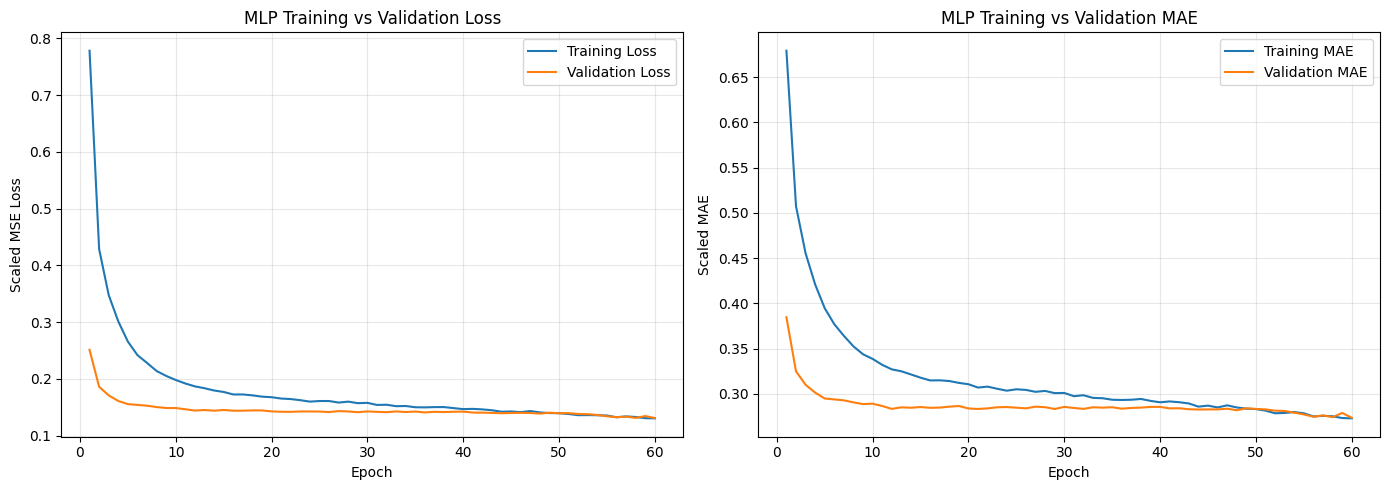

Best validation loss: 0.131
Best epoch: 60
Loss curves saved.


In [6]:

# P3 - Step 5: Training and Validation Loss Curves

history_df = pd.DataFrame(history.history)
history_df["epoch"] = np.arange(1, len(history_df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# MSE loss
axes[0].plot(
    history_df["epoch"],
    history_df["loss"],
    label="Training Loss"
)
axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)
axes[0].set_title("MLP Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Scaled MSE Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# MAE
axes[1].plot(
    history_df["epoch"],
    history_df["mae"],
    label="Training MAE"
)
axes[1].plot(
    history_df["epoch"],
    history_df["val_mae"],
    label="Validation MAE"
)
axes[1].set_title("MLP Training vs Validation MAE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Scaled MAE")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(PROJECT_DIR / "initial_training_loss_curves.png", dpi=150)
plt.show()

print("Best validation loss:", round(float(history_df["val_loss"].min()), 4))
print(
    "Best epoch:",
    int(history_df["val_loss"].idxmin() + 1)
)
print("Loss curves saved.")


In [7]:

from sklearn.model_selection import ParameterSampler
import time
import pandas as pd
import numpy as np
import tensorflow as tf

# Reproducible randomized search
search_space = {
    "hidden_units": [(64, 32), (128, 64), (128, 64, 32), (256, 128)],
    "learning_rate": [0.0003, 0.001, 0.003],
    "dropout_rate": [0.10, 0.20, 0.30],
    "l2_strength": [0.00001, 0.0001, 0.001],
    "batch_size": [64, 128]
}

candidates = list(ParameterSampler(
    search_space,
    n_iter=6,
    random_state=RANDOM_STATE
))

tuning_results = []
tuning_histories = []
tuning_start = time.time()

for trial, params in enumerate(candidates, start=1):
    print(f"\nTrial {trial}/{len(candidates)}: {params}")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(RANDOM_STATE + trial)

    model = build_mlp(
        input_dim=X_train_scaled.shape[1],
        hidden_units=params["hidden_units"],
        learning_rate=params["learning_rate"],
        dropout_rate=params["dropout_rate"],
        l2_strength=params["l2_strength"]
    )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True
    )

    start = time.time()
    trial_history = model.fit(
        X_train_scaled,
        y_train_scaled,
        validation_data=(X_val_scaled, y_val_scaled),
        epochs=35,
        batch_size=params["batch_size"],
        callbacks=[early_stop],
        verbose=0
    )

    best_val_loss = float(min(trial_history.history["val_loss"]))
    best_epoch = int(np.argmin(trial_history.history["val_loss"]) + 1)

    tuning_results.append({
        "trial": trial,
        "hidden_units": str(params["hidden_units"]),
        "learning_rate": params["learning_rate"],
        "dropout_rate": params["dropout_rate"],
        "l2_strength": params["l2_strength"],
        "batch_size": params["batch_size"],
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "training_seconds": round(time.time() - start, 2)
    })

    tuning_histories.append({
        "trial": trial,
        "params": params,
        "history": trial_history.history
    })

    print(
        f"Best validation loss: {best_val_loss:.4f} "
        f"(epoch {best_epoch})"
    )

tuning_df = pd.DataFrame(tuning_results).sort_values(
    "best_val_loss"
).reset_index(drop=True)

tuning_df.to_csv(
    PROJECT_DIR / "randomized_search_results.csv",
    index=False
)

print("\nRandomized search completed.")
print(f"Total tuning time: {(time.time() - tuning_start)/60:.2f} minutes")
display(tuning_df)
print("Results saved to randomized_search_results.csv")



Trial 1/6: {'learning_rate': 0.0003, 'l2_strength': 0.0001, 'hidden_units': (128, 64, 32), 'dropout_rate': 0.3, 'batch_size': 128}
Best validation loss: 0.1535 (epoch 35)

Trial 2/6: {'learning_rate': 0.0003, 'l2_strength': 0.001, 'hidden_units': (256, 128), 'dropout_rate': 0.3, 'batch_size': 128}
Best validation loss: 0.2726 (epoch 35)

Trial 3/6: {'learning_rate': 0.0003, 'l2_strength': 0.0001, 'hidden_units': (256, 128), 'dropout_rate': 0.1, 'batch_size': 128}
Best validation loss: 0.1536 (epoch 34)

Trial 4/6: {'learning_rate': 0.0003, 'l2_strength': 0.001, 'hidden_units': (256, 128), 'dropout_rate': 0.2, 'batch_size': 128}
Best validation loss: 0.2705 (epoch 35)

Trial 5/6: {'learning_rate': 0.0003, 'l2_strength': 0.001, 'hidden_units': (128, 64), 'dropout_rate': 0.1, 'batch_size': 64}
Best validation loss: 0.1935 (epoch 35)

Trial 6/6: {'learning_rate': 0.0003, 'l2_strength': 0.0001, 'hidden_units': (64, 32), 'dropout_rate': 0.1, 'batch_size': 128}
Best validation loss: 0.1383 (

,trial,hidden_units,learning_rate,dropout_rate,l2_strength,batch_size,best_val_loss,best_epoch,training_seconds
0,6,"(64, 32)",0.0003,0.1,0.0001,128,0.138342,34,13.85
1,1,"(128, 64, 32)",0.0003,0.3,0.0001,128,0.153515,35,20.11
2,3,"(256, 128)",0.0003,0.1,0.0001,128,0.153612,34,20.87
3,5,"(128, 64)",0.0003,0.1,0.0010,64,0.193528,35,23.04
4,4,"(256, 128)",0.0003,0.2,0.0010,128,0.270492,35,20.33
5,2,"(256, 128)",0.0003,0.3,0.0010,128,0.272636,35,21.38


Results saved to randomized_search_results.csv


In [8]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import time
import tensorflow as tf

# Select the best randomized-search configuration
best_params = candidates[
    tuning_results.index(
        next(r for r in tuning_results
             if r["trial"] == int(tuning_df.iloc[0]["trial"]))
    )
]

# Train the selected MLP
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(RANDOM_STATE)

tuned_mlp = build_mlp(
    input_dim=X_train_scaled.shape[1],
    hidden_units=best_params["hidden_units"],
    learning_rate=best_params["learning_rate"],
    dropout_rate=best_params["dropout_rate"],
    l2_strength=best_params["l2_strength"]
)

tuned_early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

mlp_start = time.time()
tuned_history = tuned_mlp.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=60,
    batch_size=best_params["batch_size"],
    callbacks=[tuned_early_stop],
    verbose=1
)
mlp_seconds = time.time() - mlp_start

# Train Random Forest baseline
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_start = time.time()
rf_model.fit(X_train, y_train)
rf_seconds = time.time() - rf_start

# Predictions in original order-volume units
mlp_val_pred = (
    tuned_mlp.predict(X_val_scaled, verbose=0).ravel()
    * target_std + target_mean
)
mlp_val_pred = np.maximum(0, mlp_val_pred)

rf_val_pred = np.maximum(0, rf_model.predict(X_val))

def regression_metrics(y_true, y_pred, model_name):
    return {
        "model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

validation_comparison = pd.DataFrame([
    regression_metrics(y_val, mlp_val_pred, "Tuned Neural Network (MLP)"),
    regression_metrics(y_val, rf_val_pred, "Random Forest Baseline")
])

validation_comparison["training_seconds"] = [
    round(mlp_seconds, 2), round(rf_seconds, 2)
]

validation_comparison.to_csv(
    PROJECT_DIR / "validation_model_comparison.csv",
    index=False
)

display(validation_comparison.round(4))
print("Validation comparison saved.")
print("MLP best epoch:", int(np.argmin(tuned_history.history["val_loss"]) + 1))


Epoch 1/60
83/83 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 1.1626 - mae: 0.8573 - val_loss: 0.5634 - val_mae: 0.6004
Epoch 2/60
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5867 - mae: 0.6039 - val_loss: 0.3109 - val_mae: 0.4369
Epoch 3/60
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4290 - mae: 0.5120 - val_loss: 0.2235 - val_mae: 0.3680
Epoch 4/60
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3812 - mae: 0.4807 - val_loss: 0.1934 - val_mae: 0.3397
Epoch 5/60
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3564 - mae: 0.4657 - val_loss: 0.1786 - val_mae: 0.3263
Epoch 6/60
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3226 - mae: 0.4423 - val_loss: 0.1710 - val_mae: 0.3187
Epoch 7/60
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3138 - mae: 0.4379 - val_loss: 0.1660 - val_mae: 0.3131
Epoch 8/60
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3012 - mae: 0.4275 - val_loss: 0.1612 - val_mae: 0.3092
Epoch 9/60
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2839 - mae:

,model,MAE,RMSE,R2,training_seconds
0,Tuned Neural Network (MLP),11.0451,13.7434,0.8789,26.19
1,Random Forest Baseline,20.6896,24.8376,0.6043,18.01


Validation comparison saved.
MLP best epoch: 51


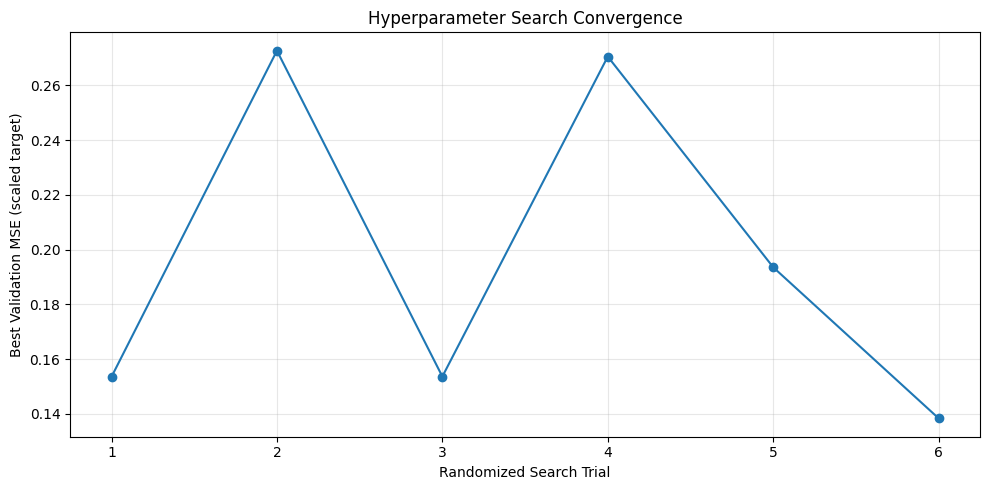

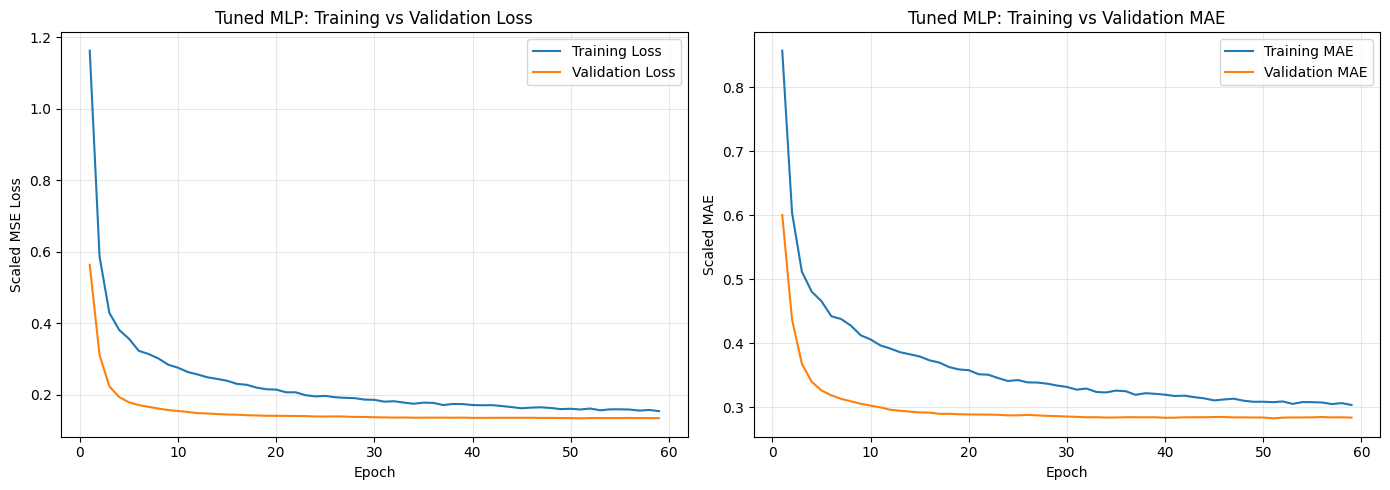

Saved:
/content/P3_Supply_Chain_Demand_Forecasting/hyperparameter_convergence.png
/content/P3_Supply_Chain_Demand_Forecasting/tuned_mlp_loss_curves.png

Best randomized-search validation loss: 0.1383
Best tuned MLP validation loss: 0.1338


In [9]:

# 1. Hyperparameter search convergence plot
search_plot_df = tuning_df.sort_values("trial")

plt.figure(figsize=(10, 5))
plt.plot(
    search_plot_df["trial"],
    search_plot_df["best_val_loss"],
    marker="o"
)
plt.xticks(search_plot_df["trial"])
plt.xlabel("Randomized Search Trial")
plt.ylabel("Best Validation MSE (scaled target)")
plt.title("Hyperparameter Search Convergence")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    PROJECT_DIR / "hyperparameter_convergence.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# 2. Tuned MLP training and validation loss curves
tuned_history_df = pd.DataFrame(tuned_history.history)
tuned_history_df["epoch"] = np.arange(1, len(tuned_history_df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    tuned_history_df["epoch"], tuned_history_df["loss"],
    label="Training Loss"
)
axes[0].plot(
    tuned_history_df["epoch"], tuned_history_df["val_loss"],
    label="Validation Loss"
)
axes[0].set_title("Tuned MLP: Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Scaled MSE Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    tuned_history_df["epoch"], tuned_history_df["mae"],
    label="Training MAE"
)
axes[1].plot(
    tuned_history_df["epoch"], tuned_history_df["val_mae"],
    label="Validation MAE"
)
axes[1].set_title("Tuned MLP: Training vs Validation MAE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Scaled MAE")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    PROJECT_DIR / "tuned_mlp_loss_curves.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("Saved:")
print(PROJECT_DIR / "hyperparameter_convergence.png")
print(PROJECT_DIR / "tuned_mlp_loss_curves.png")
print("\nBest randomized-search validation loss:",
      round(float(tuning_df["best_val_loss"].min()), 4))
print("Best tuned MLP validation loss:",
      round(float(tuned_history_df["val_loss"].min()), 4))


In [10]:

# Final evaluation on held-out test data
# Do not use the test set to tune hyperparameters.

mlp_test_pred = (
    tuned_mlp.predict(X_test_scaled, verbose=0).ravel()
    * target_std + target_mean
)
mlp_test_pred = np.maximum(0, mlp_test_pred)

rf_test_pred = np.maximum(0, rf_model.predict(X_test))

test_comparison = pd.DataFrame([
    regression_metrics(y_test, mlp_test_pred, "Tuned Neural Network (MLP)"),
    regression_metrics(y_test, rf_test_pred, "Random Forest Baseline")
])

test_comparison.to_csv(
    PROJECT_DIR / "test_model_comparison.csv",
    index=False
)

display(test_comparison.round(4))

# Save sample actual vs predicted demand values
test_predictions = pd.DataFrame({
    "actual_order_volume": y_test.to_numpy(),
    "mlp_predicted_order_volume": np.round(mlp_test_pred, 2),
    "random_forest_predicted_order_volume": np.round(rf_test_pred, 2)
})
test_predictions.to_csv(
    PROJECT_DIR / "test_predictions.csv",
    index=False
)

print("Saved test_model_comparison.csv")
print("Saved test_predictions.csv")


,model,MAE,RMSE,R2
0,Tuned Neural Network (MLP),11.0941,13.8871,0.8740
1,Random Forest Baseline,20.6021,24.8785,0.5955


Saved test_model_comparison.csv
Saved test_predictions.csv


In [11]:

import joblib
import json
from pathlib import Path

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save trained models
tuned_mlp.save(MODEL_DIR / "tuned_demand_mlp.keras")
joblib.dump(rf_model, MODEL_DIR / "random_forest_baseline.joblib")

# Save feature preprocessing information
joblib.dump(feature_scaler, MODEL_DIR / "feature_scaler.joblib")

with open(MODEL_DIR / "feature_names.json", "w") as f:
    json.dump(list(X.columns), f, indent=2)

# Save target scaling information and selected hyperparameters
final_config = {
    "project": "Supply Chain Demand Forecasting",
    "random_state": RANDOM_STATE,
    "target_column": target_column,
    "target_mean": target_mean,
    "target_std": target_std,
    "categorical_features": categorical_features,
    "numeric_features": numeric_features,
    "selected_mlp_hyperparameters": {
        "hidden_units": list(best_params["hidden_units"]),
        "learning_rate": best_params["learning_rate"],
        "dropout_rate": best_params["dropout_rate"],
        "l2_strength": best_params["l2_strength"],
        "batch_size": best_params["batch_size"]
    },
    "dataset_rows": int(len(demand_df)),
    "dataset_type": "Synthetic demonstration data"
}

with open(PROJECT_DIR / "model_config.json", "w") as f:
    json.dump(final_config, f, indent=2)

print("Models and configuration saved.")
print("\nModel files:")
for path in sorted(MODEL_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size / 1024:.1f} KB")

print("\nConfiguration saved to:", PROJECT_DIR / "model_config.json")


Models and configuration saved.

Model files:
feature_names.json: 2.3 KB
feature_scaler.joblib: 5.5 KB
random_forest_baseline.joblib: 32299.2 KB
tuned_demand_mlp.keras: 158.3 KB

Configuration saved to: /content/P3_Supply_Chain_Demand_Forecasting/model_config.json


In [12]:

# Create a standalone, reproducible training pipeline.
# It uses the saved synthetic CSV and recreates the models and reports.

pipeline_code = r'''
from pathlib import Path
import json
import random
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split, ParameterSampler
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow import keras
from tensorflow.keras import layers, regularizers

RANDOM_STATE = 42
PROJECT_DIR = Path(__file__).resolve().parent
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

df = pd.read_csv(PROJECT_DIR / "supply_chain_demand.csv")
target_column = "order_volume"
categorical_features = ["sku_id", "region", "sku_category"]
numeric_features = [
    "promotion_discount", "temperature_c", "rainfall_mm",
    "shipping_delay_days", "day_of_week", "month", "day_of_year"
]

X_raw = df[categorical_features + numeric_features].copy()
y = df[target_column].astype(float)
X = pd.get_dummies(
    X_raw, columns=categorical_features, dtype=float
)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

target_mean = float(y_train.mean())
target_std = float(y_train.std())
y_train_s = (y_train.to_numpy() - target_mean) / target_std
y_val_s = (y_val.to_numpy() - target_mean) / target_std

def build_mlp(input_dim, hidden_units, learning_rate,
              dropout_rate, l2_strength):
    model = keras.Sequential([layers.Input(shape=(input_dim,))])
    for units in hidden_units:
        model.add(layers.Dense(
            units, use_bias=False,
            kernel_regularizer=regularizers.l2(l2_strength)
        ))
        model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(1, activation="linear"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="mse", metrics=["mae"]
    )
    return model

search_space = {
    "hidden_units": [(64, 32), (128, 64), (128, 64, 32), (256, 128)],
    "learning_rate": [0.0003, 0.001, 0.003],
    "dropout_rate": [0.10, 0.20, 0.30],
    "l2_strength": [0.00001, 0.0001, 0.001],
    "batch_size": [64, 128]
}
candidates = list(ParameterSampler(
    search_space, n_iter=6, random_state=RANDOM_STATE
))

search_rows = []
search_histories = []
for trial, params in enumerate(candidates, start=1):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(RANDOM_STATE + trial)
    model = build_mlp(
        X_train_s.shape[1], params["hidden_units"],
        params["learning_rate"], params["dropout_rate"],
        params["l2_strength"]
    )
    history = model.fit(
        X_train_s, y_train_s,
        validation_data=(X_val_s, y_val_s),
        epochs=35, batch_size=params["batch_size"],
        callbacks=[keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=6, restore_best_weights=True
        )],
        verbose=0
    )
    best_loss = float(min(history.history["val_loss"]))
    search_rows.append({
        "trial": trial,
        "hidden_units": str(params["hidden_units"]),
        "learning_rate": params["learning_rate"],
        "dropout_rate": params["dropout_rate"],
        "l2_strength": params["l2_strength"],
        "batch_size": params["batch_size"],
        "best_val_loss": best_loss
    })
    search_histories.append((params, history.history))

search_df = pd.DataFrame(search_rows).sort_values("best_val_loss")
search_df.to_csv(PROJECT_DIR / "randomized_search_results.csv", index=False)
best_trial = int(search_df.iloc[0]["trial"])
best_params = candidates[best_trial - 1]

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(RANDOM_STATE)
mlp = build_mlp(
    X_train_s.shape[1], best_params["hidden_units"],
    best_params["learning_rate"], best_params["dropout_rate"],
    best_params["l2_strength"]
)
history = mlp.fit(
    X_train_s, y_train_s,
    validation_data=(X_val_s, y_val_s),
    epochs=60, batch_size=best_params["batch_size"],
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=8, restore_best_weights=True
    )],
    verbose=0
)

rf = RandomForestRegressor(
    n_estimators=200, max_depth=20, min_samples_leaf=2,
    random_state=RANDOM_STATE, n_jobs=-1
)
rf.fit(X_train, y_train)

def predict_mlp(X_scaled):
    return np.maximum(
        0, mlp.predict(X_scaled, verbose=0).ravel() * target_std + target_mean
    )

def metrics(y_true, y_pred, model_name, split):
    return {
        "split": split, "model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

rows = []
for split, true, mlp_pred, rf_pred in [
    ("validation", y_val, predict_mlp(X_val_s), np.maximum(0, rf.predict(X_val))),
    ("test", y_test, predict_mlp(X_test_s), np.maximum(0, rf.predict(X_test)))
]:
    rows.append(metrics(true, mlp_pred, "Tuned Neural Network (MLP)", split))
    rows.append(metrics(true, rf_pred, "Random Forest Baseline", split))

metrics_df = pd.DataFrame(rows)
metrics_df.to_csv(PROJECT_DIR / "model_metrics.csv", index=False)
print(metrics_df.round(4).to_string(index=False))

mlp.save(MODEL_DIR / "tuned_demand_mlp.keras")
joblib.dump(rf, MODEL_DIR / "random_forest_baseline.joblib")
joblib.dump(scaler, MODEL_DIR / "feature_scaler.joblib")
with open(MODEL_DIR / "feature_names.json", "w") as f:
    json.dump(list(X.columns), f, indent=2)

config = {
    "random_state": RANDOM_STATE,
    "target_column": target_column,
    "target_mean": target_mean,
    "target_std": target_std,
    "categorical_features": categorical_features,
    "numeric_features": numeric_features,
    "selected_mlp_hyperparameters": {
        **best_params, "hidden_units": list(best_params["hidden_units"])
    },
    "dataset_type": "Synthetic demonstration data"
}
with open(PROJECT_DIR / "model_config.json", "w") as f:
    json.dump(config, f, indent=2)

# Search convergence
plt.figure(figsize=(9, 5))
plt.plot(search_df["trial"], search_df["best_val_loss"], marker="o")
plt.xlabel("Randomized Search Trial")
plt.ylabel("Best Validation MSE (scaled target)")
plt.title("Hyperparameter Search Convergence")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PROJECT_DIR / "hyperparameter_convergence.png", dpi=150)
plt.close()

# Final MLP learning curves
hist_df = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_df["loss"], label="Training")
axes[0].plot(hist_df["val_loss"], label="Validation")
axes[0].set_title("MLP Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(hist_df["mae"], label="Training")
axes[1].plot(hist_df["val_mae"], label="Validation")
axes[1].set_title("MLP MAE (scaled target)")
axes[1].set_xlabel("Epoch")
axes[1].legend()
fig.tight_layout()
fig.savefig(PROJECT_DIR / "tuned_mlp_loss_curves.png", dpi=150)
plt.close(fig)

print("\\nPipeline complete. Artifacts saved in:", PROJECT_DIR)
'''

(PROJECT_DIR / "train_pipeline.py").write_text(pipeline_code.strip() + "\n")

readme_text = """# Supply Chain Demand Forecasting with Neural Networks

## Overview
This project demonstrates SKU-level demand forecasting using a dense feedforward
neural network (MLP) and a Random Forest regression baseline. It explores nonlinear
relationships among promotions, weather, shipping delays, calendar effects, SKU,
region, and product category.

**Important:** The included dataset is synthetic and intended for educational
demonstration. The reported metrics do not represent production performance.

## Problem statement
- Build a feedforward neural network with batch normalization and dropout.
- Tune hidden-layer dimensions, learning rate, dropout, and L2 regularization
  using randomized hyperparameter search.
- Compare the selected neural network against a Random Forest baseline.

## Dataset
- 15,000 synthetic SKU/day observations
- 100 SKUs and 5 regions
- Target: `order_volume`
- Features include promotion discount, temperature, rainfall, shipping delay,
  day of week, month, and day of year.

## Data split
- 70% training
- 15% validation
- 15% final test

Categorical variables are one-hot encoded. Input features are standardized using
a scaler fit on training data only. The target is standardized for MLP training.

## Models
### Neural network
Dense feedforward MLP with batch normalization, ReLU activations, dropout,
L2 regularization, Adam optimization, and early stopping.

### Baseline
RandomForestRegressor with 200 trees, maximum depth 20, and minimum leaf size 2.

## Test results from the Colab run

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Tuned Neural Network (MLP) | 11.0941 | 13.8871 | 0.8740 |
| Random Forest Baseline | 20.6021 | 24.8785 | 0.5955 |

Lower MAE/RMSE are better; higher R² is better. Results may differ when the
pipeline is rerun because training is stochastic and library/hardware versions vary.

## Repository contents
- `supply_chain_demand.csv`: synthetic dataset
- `train_pipeline.py`: standalone training and evaluation pipeline
- `P3_Supply_Chain_Demand_Forecasting.ipynb`: Colab notebook, if exported separately
- `randomized_search_results.csv`: hyperparameter search results
- `model_metrics.csv`: validation and test metrics from pipeline execution
- `validation_model_comparison.csv`, `test_model_comparison.csv`: notebook comparison outputs
- `test_predictions.csv`: held-out test predictions
- `hyperparameter_convergence.png`: search results visualization
- `tuned_mlp_loss_curves.png`: training and validation curves
- `models/`: saved Keras model, Random Forest, scaler, and feature names
- `model_config.json`: target scaling and selected configuration

## Run locally
Use Python 3.10–3.12 for best compatibility with TensorFlow; install dependencies:

```bash
pip install tensorflow scikit-learn pandas numpy matplotlib joblib
python train_pipeline.py
```

Place `supply_chain_demand.csv` in the project directory before running.

## Limitations
This is a synthetic demonstration, not a validated business forecasting system.
Real deployment would require historical demand, stockout and inventory data,
promotion calendars, actual weather and logistics data, time-aware evaluation,
and monitoring for model drift.
"""
(PROJECT_DIR / "README.md").write_text(readme_text.strip() + "\n")

print("Created:")
print(PROJECT_DIR / "train_pipeline.py")
print(PROJECT_DIR / "README.md")
print("Pipeline script size:", (PROJECT_DIR / "train_pipeline.py").stat().st_size, "bytes")


Created:
/content/P3_Supply_Chain_Demand_Forecasting/train_pipeline.py
/content/P3_Supply_Chain_Demand_Forecasting/README.md
Pipeline script size: 7468 bytes


In [13]:

from pathlib import Path
import pandas as pd
import json
import os

print("PROJECT DIRECTORY:", PROJECT_DIR)
print("\n--- Required deliverables ---")

required_files = [
    "supply_chain_demand.csv",
    "train_pipeline.py",
    "README.md",
    "model_config.json",
    "randomized_search_results.csv",
    "validation_model_comparison.csv",
    "test_model_comparison.csv",
    "test_predictions.csv",
    "hyperparameter_convergence.png",
    "tuned_mlp_loss_curves.png",
    "initial_training_loss_curves.png",
    "models/tuned_demand_mlp.keras",
    "models/random_forest_baseline.joblib",
    "models/feature_scaler.joblib",
    "models/feature_names.json"
]

verification = []
for filename in required_files:
    path = PROJECT_DIR / filename
    verification.append({
        "file": filename,
        "exists": path.exists(),
        "size_kb": round(path.stat().st_size / 1024, 2)
                    if path.exists() and path.is_file() else None
    })

verification_df = pd.DataFrame(verification)
display(verification_df)
print("\nAll required files present:", bool(verification_df["exists"].all()))

# Check dataset and results
dataset = pd.read_csv(PROJECT_DIR / "supply_chain_demand.csv")
print("\n--- Dataset validation ---")
print("Rows:", len(dataset))
print("Unique SKUs:", dataset["sku_id"].nunique())
print("Regions:", dataset["region"].nunique())
print("Missing values:", int(dataset.isna().sum().sum()))
print("Target:", "order_volume")
print("Target minimum:", dataset["order_volume"].min())

# Check saved model configuration
with open(PROJECT_DIR / "model_config.json") as f:
    saved_config = json.load(f)
print("\n--- Selected MLP configuration ---")
print(json.dumps(saved_config["selected_mlp_hyperparameters"], indent=2))

# Check final evaluation report
print("\n--- Test comparison ---")
display(pd.read_csv(PROJECT_DIR / "test_model_comparison.csv").round(4))

# Report missing files clearly
missing = verification_df.loc[~verification_df["exists"], "file"].tolist()
if missing:
    print("\nMISSING FILES — we will address these before packaging:")
    for name in missing:
        print("-", name)
else:
    print("\nVerification passed: all listed files are present.")


PROJECT DIRECTORY: /content/P3_Supply_Chain_Demand_Forecasting

--- Required deliverables ---


,file,exists,size_kb
0,supply_chain_demand.csv,True,947.07
1,train_pipeline.py,True,7.29
2,README.md,True,3.12
3,model_config.json,True,0.68
4,randomized_search_results.csv,True,0.49
5,validation_model_comparison.csv,True,0.21
6,test_model_comparison.csv,True,0.18
7,test_predictions.csv,True,38.00
8,hyperparameter_convergence.png,True,79.01
9,tuned_mlp_loss_curves.png,True,88.33



All required files present: True

--- Dataset validation ---
Rows: 15000
Unique SKUs: 100
Regions: 5
Missing values: 0
Target: order_volume
Target minimum: 0

--- Selected MLP configuration ---
{
  "hidden_units": [
    64,
    32
  ],
  "learning_rate": 0.0003,
  "dropout_rate": 0.1,
  "l2_strength": 0.0001,
  "batch_size": 128
}

--- Test comparison ---


,model,MAE,RMSE,R2
0,Tuned Neural Network (MLP),11.0941,13.8871,0.8740
1,Random Forest Baseline,20.6021,24.8785,0.5955



Verification passed: all listed files are present.
